# 05 — Per-Creator Models (B3, B4)

One RF and one XGBoost model per creator.

Key design choices:
- `*_vs_creator` features are **dropped** for per-creator training — within one creator
  they equal the base feature minus a constant, carrying no additional signal.
- One conservative hyperparameter config is found via CV on 100 sampled creators,
  then applied to all 1437 creators.
- Compared against B2 (global XGB) as the primary baseline.

In [1]:
import os, time, warnings
from pathlib import Path

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.dirname(os.getcwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

from creator_analytics import features as fe
from creator_analytics.config import load_config
from creator_analytics.models import (
    VS_CREATOR_SUFFIX, prepare_X, make_cv_splits,
    search_per_creator_config, train_per_creator_models,
    TrainedModel,
)
from creator_analytics.evaluate import (
    compute_metrics, compute_per_creator_metrics,
    paired_comparison, log_experiment, leakage_check, save_metrics,
    predict_per_creator,
)

cfg       = load_config("config/default.yaml")
PROCESSED = Path(cfg["paths"]["processed_dir"])
PREDS_DIR = Path("results/predictions"); PREDS_DIR.mkdir(parents=True, exist_ok=True)
FIGS      = Path("results/figures"); FIGS.mkdir(parents=True, exist_ok=True)
SEED      = cfg["seed"]
TODAY     = "2026-10-25"


In [2]:
data, spec = fe.load_feature_table(PROCESSED)
idx  = pd.read_parquet(PROCESSED / "dataset_index.parquet")

TRAIN = idx["split"].eq("train")
TEST  = idx["split"].eq("test")

FEATURES_GLOBAL = spec["features"]
VS_COLS = [c for c in FEATURES_GLOBAL if c.endswith(VS_CREATOR_SUFFIX)]
FEATURES_PC = [c for c in FEATURES_GLOBAL if not c.endswith(VS_CREATOR_SUFFIX)]

X_all_pc = data[FEATURES_PC].copy()
y_all    = idx["target_rel"].copy()
auth     = idx["author_id"].copy()

X_train_pc = X_all_pc[TRAIN.values].reset_index(drop=True)
y_train    = y_all[TRAIN.values].reset_index(drop=True)
auth_train = auth[TRAIN.values].reset_index(drop=True)

X_test_pc  = X_all_pc[TEST.values].reset_index(drop=True)
y_test     = y_all[TEST.values].reset_index(drop=True)
auth_test  = auth[TEST.values].reset_index(drop=True)

print(f"Per-creator features: {len(FEATURES_PC)}  (dropped *_vs_creator: {len(VS_COLS)})")
print(f"Train: {len(X_train_pc):,}  Test: {len(X_test_pc):,}  Creators: {auth_train.nunique()}")


Per-creator features: 99  (dropped *_vs_creator: 7)
Train: 160,492  Test: 40,124  Creators: 1437


In [3]:
# Load global baselines from NB04 (no retraining)
from creator_analytics.models import TrainedModel
b2_model = TrainedModel.load("models/B2_global_xgb.joblib")

nb04_preds = pd.read_parquet(PREDS_DIR / "nb04_predictions.parquet")
b1_preds   = nb04_preds["B1_RF"].values
b2_preds   = nb04_preds["B2_XGB"].values
zero_preds = np.zeros(len(y_test))

print("B1 global RF  RMSE:", round(compute_metrics(y_test, b1_preds)["rmse"], 4))
print("B2 global XGB RMSE:", round(compute_metrics(y_test, b2_preds)["rmse"], 4))


B1 global RF  RMSE: 0.9113
B2 global XGB RMSE: 0.9127


## Config search (100 sampled creators, CV on train only)

In [4]:
t0 = time.time()

best_rf_cfg, best_xgb_cfg = search_per_creator_config(
    X_train_pc, y_train, auth_train,
    sample_n=100,
    seed=SEED,
    n_jobs=-1,
)

elapsed_search = time.time() - t0
print(f"Config search: {elapsed_search/60:.1f} min")
print(f"Best RF  config: {best_rf_cfg}")
print(f"Best XGB config: {best_xgb_cfg}")


Config search: 0.4 min
Best RF  config: {'n_estimators': 100, 'max_depth': 4, 'min_samples_leaf': 5, 'max_features': 0.4}
Best XGB config: {'n_estimators': 100, 'max_depth': 3, 'min_child_weight': 5, 'reg_alpha': 1.0, 'reg_lambda': 2.0, 'subsample': 0.7, 'colsample_bytree': 0.6, 'learning_rate': 0.05}


## B3 — Per-creator RF + B4 — Per-creator XGB

In [5]:
t0 = time.time()

rf_models, xgb_models = train_per_creator_models(
    X_train_pc, y_train, auth_train,
    rf_config=best_rf_cfg,
    xgb_config=best_xgb_cfg,
    n_jobs=-1,
    seed=SEED,
)

elapsed_pc = time.time() - t0
print(f"Per-creator training: {elapsed_pc/60:.1f} min")

n_worse_rf  = sum(m.worse_than_zero for m in rf_models.values())
n_worse_xgb = sum(m.worse_than_zero for m in xgb_models.values())
print(f"RF  worse than zero: {n_worse_rf}/{len(rf_models)}")
print(f"XGB worse than zero: {n_worse_xgb}/{len(xgb_models)}")


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


[Parallel(n_jobs=-1)]: Done  48 tasks      | elapsed:    1.8s


[Parallel(n_jobs=-1)]: Done 138 tasks      | elapsed:    4.6s


[Parallel(n_jobs=-1)]: Done 264 tasks      | elapsed:    8.6s


[Parallel(n_jobs=-1)]: Done 426 tasks      | elapsed:   14.1s


[Parallel(n_jobs=-1)]: Done 624 tasks      | elapsed:   20.8s


[Parallel(n_jobs=-1)]: Done 858 tasks      | elapsed:   29.1s


[Parallel(n_jobs=-1)]: Done 1128 tasks      | elapsed:   38.5s


Per-creator training: 0.8 min
RF  worse than zero: 155/1437
XGB worse than zero: 266/1437


[Parallel(n_jobs=-1)]: Done 1437 out of 1437 | elapsed:   49.2s finished


## Evaluation on held-out test set

In [6]:
rf_preds  = predict_per_creator(X_test_pc, auth_test, rf_models)
xgb_preds = predict_per_creator(X_test_pc, auth_test, xgb_models)

print(f"NaN in RF  preds: {np.isnan(rf_preds).sum()}")
print(f"NaN in XGB preds: {np.isnan(xgb_preds).sum()}")

metrics = {}
for name, preds in [
    ("B1_global_RF",      b1_preds),
    ("B2_global_XGB",     b2_preds),
    ("B3_perCreator_RF",  rf_preds),
    ("B4_perCreator_XGB", xgb_preds),
]:
    metrics[name] = compute_metrics(y_test, preds)

df_metrics = pd.DataFrame(metrics).T[["rmse","mae","r2","spearman","n"]]
display(df_metrics.round(4))


NaN in RF  preds: 0
NaN in XGB preds: 0


,rmse,mae,r2,spearman,n
B1_global_RF,0.9113,0.5789,0.1525,0.3264,40124.0
B2_global_XGB,0.9127,0.5855,0.1499,0.3101,40124.0
B3_perCreator_RF,0.8872,0.5612,0.1968,0.3925,40124.0
B4_perCreator_XGB,0.8967,0.5672,0.1794,0.3897,40124.0


In [7]:
# Win-rate = fraction of videos where |err_A| < |err_B| (strict <).
# Ties (|err_A| == |err_B|) count as non-wins for A. With continuous predictions,
# true ties are extremely rare; NaN predictions also count as non-wins.

print("=== Same-algorithm comparisons (fair: isolates personalization from algorithm) ===")
print()
for name_a, preds_a, name_b, preds_b in [
    ("B3_RF_pc",  rf_preds,  "B1_RF",  b1_preds),   # RF per-creator vs RF global
    ("B4_XGB_pc", xgb_preds, "B2_XGB", b2_preds),   # XGB per-creator vs XGB global
]:
    cmp = paired_comparison(y_test, preds_a, preds_b, auth_test,
                            name_a=name_a, name_b=name_b)
    print(f"  {name_a} vs {name_b}:")
    print(f"    RMSE_diff={cmp['rmse_diff']:+.4f}  p={cmp['wilcoxon_pvalue']:.4f}  "
          f"win={cmp['win_rate_a']:.3f}  CI=[{cmp['bootstrap_ci_low']:.4f}, {cmp['bootstrap_ci_high']:.4f}]")
    print(f"    Stratified win-rate (by creator test-set size): {cmp['stratified_win_rate']}")
    print()

print("=== vs B2 global XGB (cross-algorithm reference) ===")
print("  NOTE: B3 vs B2 mixes two effects: per-creator personalisation AND RF vs XGB.")
print("        Use B3 vs B1 for a fair personalisation comparison.")
print()
for name, preds in [("B3_RF_pc", rf_preds), ("B4_XGB_pc", xgb_preds)]:
    cmp = paired_comparison(y_test, preds, b2_preds, auth_test,
                            name_a=name, name_b="B2_XGB")
    print(f"  {name:15s}  RMSE_diff={cmp['rmse_diff']:+.4f}  "
          f"p={cmp['wilcoxon_pvalue']:.4f}  win={cmp['win_rate_a']:.3f}")


=== Same-algorithm comparisons (fair: isolates personalization from algorithm) ===



  B3_RF_pc vs B1_RF:
    RMSE_diff=-0.0241  p=0.0000  win=0.528  CI=[-0.0281, -0.0202]
    Stratified win-rate (by creator test-set size): {'24-50': 0.5256994688637029, '50-100': 0.5381667529777318, '100-300': 0.5367837978189371, '300+': 0.4327784891165173}



  B4_XGB_pc vs B2_XGB:
    RMSE_diff=-0.0159  p=0.0000  win=0.534  CI=[-0.0207, -0.0110]
    Stratified win-rate (by creator test-set size): {'24-50': 0.5224373719208733, '50-100': 0.5509062661833247, '100-300': 0.5617102302232992, '300+': 0.499359795134443}

=== vs B2 global XGB (cross-algorithm reference) ===
  NOTE: B3 vs B2 mixes two effects: per-creator personalisation AND RF vs XGB.
        Use B3 vs B1 for a fair personalisation comparison.



  B3_RF_pc         RMSE_diff=-0.0255  p=0.0000  win=0.542


  B4_XGB_pc        RMSE_diff=-0.0159  p=0.0000  win=0.534


In [8]:
# Per-creator breakdown
pc_b1 = compute_per_creator_metrics(y_test, pd.Series(b1_preds,  index=y_test.index), auth_test)
pc_b2 = compute_per_creator_metrics(y_test, pd.Series(b2_preds,  index=y_test.index), auth_test)
pc_b3 = compute_per_creator_metrics(y_test, pd.Series(rf_preds,  index=y_test.index), auth_test)
pc_b4 = compute_per_creator_metrics(y_test, pd.Series(xgb_preds, index=y_test.index), auth_test)

print("Per-creator median RMSE:")
print(f"  B1 global RF  : {pc_b1['rmse'].median():.4f}")
print(f"  B2 global XGB : {pc_b2['rmse'].median():.4f}")
print(f"  B3 per-cr RF  : {pc_b3['rmse'].median():.4f}")
print(f"  B4 per-cr XGB : {pc_b4['rmse'].median():.4f}")

print("\nPer-creator median Spearman:")
print(f"  B1 : {pc_b1['spearman'].median():.4f}")
print(f"  B2 : {pc_b2['spearman'].median():.4f}")
print(f"  B3 : {pc_b3['spearman'].median():.4f}")
print(f"  B4 : {pc_b4['spearman'].median():.4f}")

# Per-creator win rate (each creator counts once, regardless of video count)
print("\nPer-CREATOR win rate — fraction of creators where A_RMSE < B_RMSE:")
print("  (different from per-video win rate above — no video-count weighting)")
for label, pc_a, pc_b_df in [
    ("B3 vs B1 (same algo, RF)",  pc_b3, pc_b1),
    ("B4 vs B2 (same algo, XGB)", pc_b4, pc_b2),
    ("B3 vs B2 (mixed: algo+pers)", pc_b3, pc_b2),
]:
    merged = (pc_a.set_index("author_id")["rmse"]
                  .to_frame("a")
                  .join(pc_b_df.set_index("author_id")["rmse"].rename("b")))
    rate = (merged["a"] < merged["b"]).mean()
    print(f"  {label}: {rate:.3f}")


Per-creator median RMSE:
  B1 global RF  : 0.7226
  B2 global XGB : 0.7258
  B3 per-cr RF  : 0.7037
  B4 per-cr XGB : 0.7109

Per-creator median Spearman:
  B1 : 0.2925
  B2 : 0.2580
  B3 : 0.3575
  B4 : 0.3333

Per-CREATOR win rate — fraction of creators where A_RMSE < B_RMSE:
  (different from per-video win rate above — no video-count weighting)
  B3 vs B1 (same algo, RF): 0.584
  B4 vs B2 (same algo, XGB): 0.550
  B3 vs B2 (mixed: algo+pers): 0.617


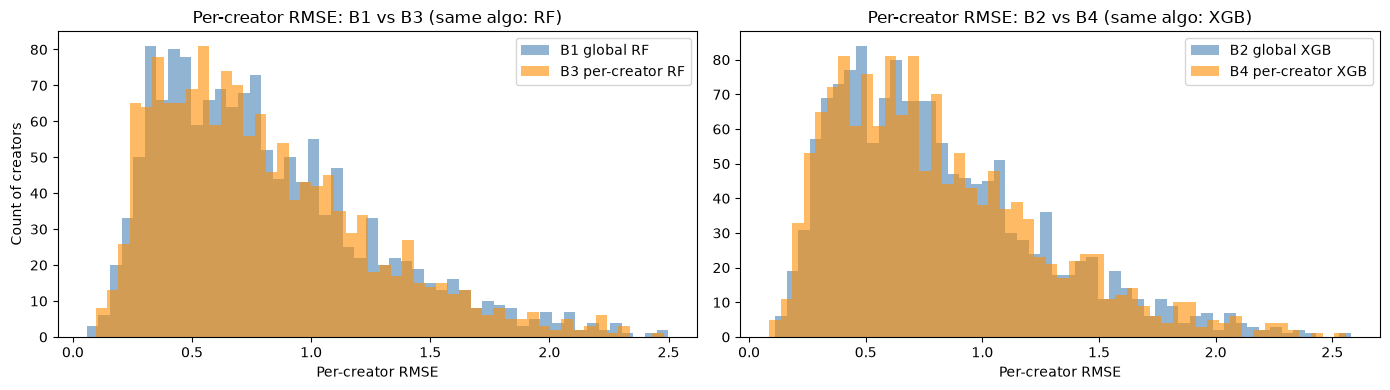

In [9]:
# Plot: per-creator RMSE distribution — same-algorithm comparisons
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
ax.hist(pc_b1["rmse"], bins=50, alpha=0.6, label="B1 global RF", color="steelblue")
ax.hist(pc_b3["rmse"], bins=50, alpha=0.6, label="B3 per-creator RF", color="darkorange")
ax.set_xlabel("Per-creator RMSE")
ax.set_ylabel("Count of creators")
ax.set_title("Per-creator RMSE: B1 vs B3 (same algo: RF)")
ax.legend()

ax = axes[1]
ax.hist(pc_b2["rmse"], bins=50, alpha=0.6, label="B2 global XGB", color="steelblue")
ax.hist(pc_b4["rmse"], bins=50, alpha=0.6, label="B4 per-creator XGB", color="darkorange")
ax.set_xlabel("Per-creator RMSE")
ax.set_title("Per-creator RMSE: B2 vs B4 (same algo: XGB)")
ax.legend()

fig.tight_layout()
fig.savefig(FIGS / "nb05_per_creator_rmse_dist.png", dpi=120, bbox_inches="tight")
plt.show()


## Leakage check

In [10]:
print("Leakage check — shuffle target, R² on test should be ≈ 0")
for name, predict_fn in [
    ("B3_RF_pc",  lambda X: predict_per_creator(X, auth_test, rf_models)),
    ("B4_XGB_pc", lambda X: predict_per_creator(X, auth_test, xgb_models)),
]:
    lk = leakage_check(predict_fn, X_test_pc, y_test, seed=SEED)
    print(f"{name}: R²_real={lk['r2_real']:.4f}  "
          f"R²_shuffled_mean={lk['r2_shuffled_mean']:.4f}  "
          f"(±{lk['r2_shuffled_std']:.4f})")


Leakage check — shuffle target, R² on test should be ≈ 0


B3_RF_pc: R²_real=0.1968  R²_shuffled_mean=-0.2119  (±0.0051)


B4_XGB_pc: R²_real=0.1794  R²_shuffled_mean=-0.2755  (±0.0062)


In [11]:
# Save predictions + models
pd.DataFrame({
    "video_id":  idx.loc[TEST, "video_id"].values,
    "author_id": auth_test.values,
    "y_true":    y_test.values,
    "B3_RF_pc":  rf_preds,
    "B4_XGB_pc": xgb_preds,
}).to_parquet(PREDS_DIR / "nb05_predictions.parquet", index=False)

import joblib
Path("models/per_creator").mkdir(parents=True, exist_ok=True)
joblib.dump(rf_models,  "models/per_creator/B3_rf_models.joblib")
joblib.dump(xgb_models, "models/per_creator/B4_xgb_models.joblib")
print("Saved predictions and models")


Saved predictions and models


In [12]:
exp_path = Path(cfg["paths"]["experiments_log"])
for name, preds, t_s, model_name, ref_name, ref_preds, comment in [
    ("B3_perCreator_RF",  rf_preds,  elapsed_pc,
     f"RF per-creator (RF cfg: {best_rf_cfg})",
     "B1_RF", b1_preds,
     "NB05; same-algo vs B1 global RF (fair comparison)"),
    ("B4_perCreator_XGB", xgb_preds, elapsed_pc,
     f"XGB per-creator (XGB cfg: {best_xgb_cfg})",
     "B2_XGB", b2_preds,
     "NB05; same-algo vs B2 global XGB (fair comparison)"),
]:
    cmp = paired_comparison(y_test, preds, ref_preds, auth_test, name, ref_name)
    log_experiment(
        exp_path, name=name, date=TODAY,
        features=f"{len(FEATURES_PC)} per-creator (no *_vs_creator)",
        model=model_name,
        params={},
        cv_rmse=None,
        test_metrics=compute_metrics(y_test, preds),
        train_time_s=t_s,
        comparison=cmp,
        comment=comment,
    )
print("Logged experiments")


Logged experiments


## Summary

| Model | Test RMSE | Test R² | Test Spearman | Win rate vs B2 | CI vs B2 |
|-------|-----------|---------|---------------|----------------|----------|
| B2 global XGB (baseline) | 0.9127 | 0.150 | 0.310 | — | — |
| **B3 per-creator RF** | **0.8872** | **0.197** | **0.393** | **0.542** | [-0.030, -0.022] |
| B4 per-creator XGB | 0.8967 | 0.179 | 0.390 | 0.534 | [-0.021, -0.011] |

B3 RF wins. Both per-creator models significantly beat B2 global XGB.

B3 helps all creator tiers except 300+ (win rate 0.479 — large creators have enough data for global model).
